In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import matplotlib.patches as patches


# ==============================================================================
# CELL 1: CONFIGURATION & STYLE
# ==============================================================================
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


In [2]:
from pathlib import Path

# Sobe a partir do cwd até achar a raiz do projeto (a pasta que contém tools/)
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())

DATA_DIR = PROJ_ROOT / "data_TNG50-4_snap025_5runs"   # nome que o launcher criou
GRID_DIR = Path.cwd() / "data_grid"                    # continua em notebooks_TNG/

print("projeto :", PROJ_ROOT)
print("dados   :", DATA_DIR, "|", len(list(DATA_DIR.glob('*.pkl'))), "pkl encontrados")

projeto : /home/vroberto/FakeSpectra_DLAs
dados   : /home/vroberto/FakeSpectra_DLAs/data_TNG50-4_snap025_5runs | 5 pkl encontrados


In [3]:
# ==============================================================================
# CELL 2: LOAD GRID DATA & COMPUTE GLOBAL FRACTIONS
# ==============================================================================
grid_file_path = 'data_grid/TNG50-4_z3_Grid_500x500_DLAMode.pkl'

print("Loading the Grid file...")
df_grid = pd.read_pickle(grid_file_path)

# Binning thresholds for absorber categories
bins_grid   = [0, 1.6e17, 1e19, 2e20, 1e21, np.inf]
labels_grid = ['Forest', 'LLS', 'Sub_DLA', 'Small_DLA', 'Large_DLA']

df_grid['category'] = pd.cut(
    df_grid['total_col_den'], bins=bins_grid, labels=labels_grid, right=False
)

total_grid_skewers = len(df_grid)
grid_counts    = df_grid['category'].value_counts(sort=False)
grid_fractions = grid_counts / total_grid_skewers

print(f"Grid Data Processed: {total_grid_skewers:,} skewers.")

Loading the Grid file...
Grid Data Processed: 750,000 skewers.


In [4]:
# ==============================================================================
# CELL 3: LOAD, MERGE & PREPARE ALL VARIANCE RUNS (original + extended)
# ==============================================================================
data_dir = DATA_DIR

# --- Discover all original run files ---
orig_pattern = os.path.join(data_dir, 'TNG50-4_z3_*_HCDMode_Stratified_run*.pkl')
orig_files   = sorted(glob.glob(orig_pattern))

# --- Discover all extended run files ---
ext_pattern = os.path.join(data_dir, 'Extended_TNG50-4_z3_*_HCDMode_Stratified_run*.pkl')
ext_files   = sorted(glob.glob(ext_pattern))

# Filter out the "Extended_" files from the original list (glob might catch both)
orig_files = [f for f in orig_files if 'Extended_' not in os.path.basename(f)]

if len(orig_files) == 0:
    raise FileNotFoundError(f"No original run files found in {data_dir}!")

print(f"\nFound {len(orig_files)} original files and {len(ext_files)} extension files.")

# --- Build a lookup from run_id -> extension file ---
# Extract run_id from filenames like "Extended_..._run3_seed999.pkl"
def extract_run_id(filepath):
    """Pull the integer run_id from a filename containing '_runX_'."""
    basename = os.path.basename(filepath)
    for part in basename.split('_'):
        if part.startswith('run'):
            return int(part.replace('run', ''))
    return None

ext_lookup = {}
for ef in ext_files:
    rid = extract_run_id(ef)
    if rid is not None:
        ext_lookup[rid] = ef

# --- Merge each original with its extension (if available) ---
dfs_runs = []

for of in orig_files:
    rid = extract_run_id(of)
    df_orig = pd.read_pickle(of)

    if rid in ext_lookup:
        df_ext = pd.read_pickle(ext_lookup[rid])

        # Sanity check: no overlapping impact parameters
        orig_radii = set(df_orig['r_multiplier'].round(2).unique())
        ext_radii  = set(df_ext['r_multiplier'].round(2).unique())
        assert orig_radii.isdisjoint(ext_radii), (
            f"Run {rid}: overlap detected between original and extension radii!"
        )

        df_merged = pd.concat([df_orig, df_ext], ignore_index=True)
        df_merged = df_merged.sort_values(by=['halo_id', 'r_multiplier', 'skewer_id'])
        tag = "merged"
    else:
        df_merged = df_orig
        tag = "original only (no extension found)"

    df_merged['r_mult_round'] = df_merged['r_multiplier'].round(2)
    dfs_runs.append(df_merged)

    print(f"  Run {rid}: {len(df_orig):>7,} orig + "
          f"{len(df_merged)-len(df_orig):>6,} ext = "
          f"{len(df_merged):>7,} total  [{tag}]")

# All runs should share the same set of impact parameters
unique_radii = np.sort(dfs_runs[0]['r_mult_round'].unique())
n_runs       = len(dfs_runs)

print(f"\n{n_runs} runs loaded.  Impact parameters ({len(unique_radii)}):")
print(f"  {unique_radii}")


Found 5 original files and 0 extension files.
  Run 0: 231,231 orig +      0 ext = 231,231 total  [original only (no extension found)]
  Run 1: 231,231 orig +      0 ext = 231,231 total  [original only (no extension found)]
  Run 2: 231,231 orig +      0 ext = 231,231 total  [original only (no extension found)]
  Run 3: 231,231 orig +      0 ext = 231,231 total  [original only (no extension found)]
  Run 4: 231,231 orig +      0 ext = 231,231 total  [original only (no extension found)]

5 runs loaded.  Impact parameters (29):
  [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]


In [5]:
# ==============================================================================
# CELL 4: CALCULATE FRACTIONS & VARIANCE PER IMPACT PARAMETER
# ==============================================================================
cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v',
                  'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o',
                  'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's',
                  'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^',
                  'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'},
}

# Collect fraction profiles: shape will be (n_runs, n_radii) per category
fractions_raw = {cat: [] for cat in cat_styles}

for df_run in dfs_runs:
    run_fracs = {cat: [] for cat in cat_styles}

    for b_val in unique_radii:
        df_b = df_run[df_run['r_mult_round'] == b_val]
        tot  = len(df_b)

        if tot > 0:
            nhi = df_b['log_n_hi']
            run_fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
            run_fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
            run_fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
            run_fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
            run_fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
        else:
            for cat in cat_styles:
                run_fracs[cat].append(0.0)

    for cat in cat_styles:
        fractions_raw[cat].append(run_fracs[cat])

# Convert to numpy arrays for vectorized stats
for cat in cat_styles:
    fractions_raw[cat] = np.array(fractions_raw[cat])

/tmp/ipykernel_1879802/3082634350.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


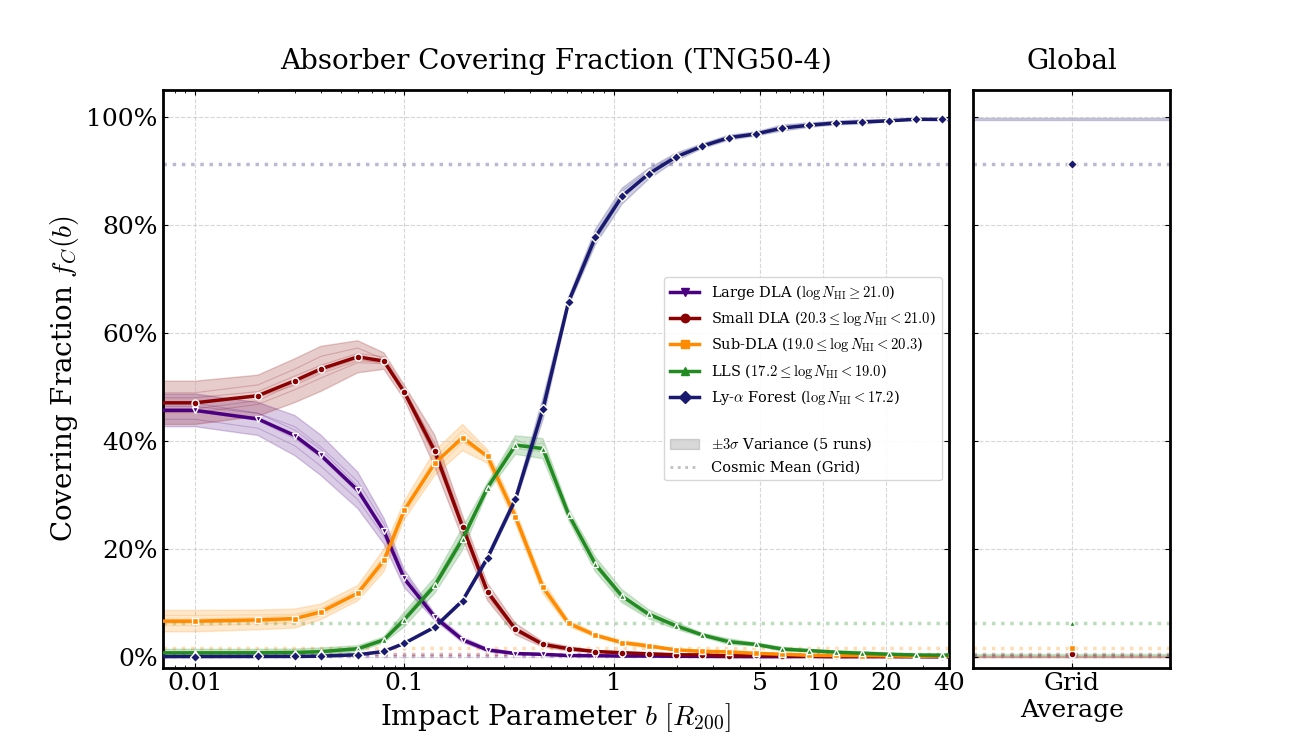

In [6]:
# ==============================================================================
# CELL 5: COMBINED PLOT (PROFILES + GRID PANEL, ±3σ SHADING, UP TO 20 R200)
# ==============================================================================
NSIGMA = 3  # <-- Change this single number for 1σ, 2σ, etc.

fig, (ax_main, ax_grid) = plt.subplots(
    1, 2, figsize=(13, 7.5),
    sharey=True,
    gridspec_kw={'width_ratios': [4, 1], 'wspace': 0.05},
)

for cat, style in cat_styles.items():
    data_matrix = fractions_raw[cat]  # (n_runs, n_radii)

    mean_frac = np.mean(data_matrix, axis=0)
    std_frac  = np.std(data_matrix, axis=0)

    # ±Nσ shading on main panel
    ax_main.fill_between(
        unique_radii,
        np.clip(mean_frac - NSIGMA * std_frac, 0, None),
        np.clip(mean_frac + NSIGMA * std_frac, None, 1),
        color=style['color'], alpha=0.20, zorder=1,
    )

    # Individual runs (thin, faint)
    for run_idx in range(data_matrix.shape[0]):
        ax_main.plot(
            unique_radii, data_matrix[run_idx, :],
            color=style['color'], alpha=0.20, lw=0.8, ls='-', zorder=2,
        )

    # Mean line (bold markers)
    ax_main.plot(
        unique_radii, mean_frac,
        color=style['color'], lw=2.5, ls='-',
        marker=style['marker'], ms=5, mec='white', zorder=3,
    )

# --- Side panel: Grid averages & variance extension ---
x_pos_grid = 1.0

for cat, style in cat_styles.items():
    grid_val = grid_fractions[cat]

    data_matrix = fractions_raw[cat]
    last_mean = np.mean(data_matrix, axis=0)[-1]
    last_std  = np.std(data_matrix, axis=0)[-1]

    # Extend the ±Nσ band into the side panel
    ax_grid.axhspan(
        np.clip(last_mean - NSIGMA * last_std, 0, None),
        np.clip(last_mean + NSIGMA * last_std, None, 1),
        color=style['color'], alpha=0.20, zorder=1,
    )

    # Grid marker
    ax_grid.plot(
        x_pos_grid, grid_val,
        color=style['color'], marker=style['marker'],
        ms=5, mec='white', zorder=3,
    )

    # Cosmic-mean dotted lines spanning both panels
    ax_main.axhline(grid_val, color=style['color'], ls=':', alpha=0.3, zorder=0)
    ax_grid.axhline(grid_val, color=style['color'], ls=':', alpha=0.3, zorder=0)

# --- Aesthetics: main panel ---
ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 40.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '40'])
ax_main.set_xlim(unique_radii[unique_radii > 0].min() * 0.7, 40)

ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(r'Absorber Covering Fraction (TNG50-4)', pad=15)

# --- Aesthetics: side panel ---
ax_grid.grid(True, ls='--', alpha=0.5)
ax_grid.set_xlim(0.8, 1.2)
ax_grid.set_xticks([x_pos_grid])
ax_grid.set_xticklabels(['Grid\nAverage'])
ax_grid.set_title('Global', pad=15)

# --- Composite legend ---
legend_elements = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], label=c['label'])
    for c in cat_styles.values()
]
legend_elements.append(Line2D([0], [0], color='none', label=' '))
legend_elements.append(
    patches.Patch(
        facecolor='gray', alpha=0.3, edgecolor='gray',
        label=rf'$\pm {NSIGMA}\sigma$ Variance ({n_runs} runs)',
    )
)
legend_elements.append(
    Line2D([0], [0], color='gray', ls=':', alpha=0.5, lw=2,
           label='Cosmic Mean (Grid)')
)

ax_main.legend(
    handles=legend_elements, loc='center right', frameon=True,
    fontsize=10.5, edgecolor='lightgray', facecolor='white', framealpha=0.9,
)

plt.tight_layout()
plt.show()

# Ridgeline Plots!

In [7]:
# Ridgeline Plots!
# ==============================================================================
# CELL 7: RIDGELINE — VARIANCE ACROSS RUNS (DENSITY-NORMALIZED, ALIGNED EDGES)
# ==============================================================================

# --------------------------------------------------------------------------
# 0. Configuration
# --------------------------------------------------------------------------
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

for df_run in dfs_runs:
    if 'halo_mass_msun' not in df_run.columns:
        df_run['halo_mass_msun'] = df_run['halo_mass'] * MASS_CONVERSION_FACTOR

# Filter impact parameters: keep 0.0, up to 2.0 R200
SELECTED_B = sorted(unique_radii[unique_radii >= 0.0])
SELECTED_B = [b for b in SELECTED_B if b <= 2.0]
print(f"Impact parameters for ridgeline ({len(SELECTED_B)}):\n  {SELECTED_B}")

# Mass bins
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**12.0, 10**13.0]
mass_labels = [
    r'$10^{10.0} \leq M_{200} < 10^{10.5} \; M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11.0} \; M_\odot$',
    r'$10^{11.0} \leq M_{200} < 10^{11.5} \; M_\odot$',
    r'$10^{11.5} \leq M_{200} < 10^{12.0} \; M_\odot$',
    r'$10^{12.0} \leq M_{200} < 10^{13.0} \; M_\odot$',
]
n_mass_bins = len(mass_labels)

# Background region colours
c_forest   = '#E3F2FD'
c_lls      = '#E8F5E9'
c_subdla   = '#FFF3E0'
c_smalldla = '#FFCDD2'
c_largedla = '#E1BEE7'

# Run colours
run_colors = ['tab:red', 'tab:blue', 'tab:green', 'tab:orange', 'tab:purple']

# ----------------------------------------------------------------------------
# overlap_factor: COSMETIC VERTICAL SCALING.
# Each ridgeline curve is drawn above an integer y-base. With density-per-dex
# normalization the natural curve heights are small (~0.5-2.0), so we multiply
# by overlap_factor to make the curves visually prominent. It does NOT distort
# relative areas: the area between two log N_HI limits equals the fraction of
# skewers in that interval (exactly the covering-fraction quantity).
# Typical good values: 2.0 - 4.0. Bigger = more overlap between rows.
# ----------------------------------------------------------------------------
overlap_factor = 1.8
NSIGMA_RIDGE   = 1    # 1 standard deviation
n_sel          = len(SELECTED_B)

# Histogram definitions (restricted to 16.0 -> 23.0)
num_bins  = 100
hist_bins = np.linspace(16.0, 23.0, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]   # constant since we use linspace


# --------------------------------------------------------------------------
# CORRECTED HISTOGRAM: density per dex (dn / d log N_HI / N_total)
# --------------------------------------------------------------------------
def density_hist(values, bins, tot_skewers):
    """
    Returns probability density per unit log N_HI.
    
    Height in each bin = (counts_in_bin / total_skewers) / bin_width
    
    Properties:
    - Integral over the entire range = fraction of skewers with valid log_n_hi.
    - Integral over any sub-range [a, b] = fraction of skewers with log N_HI in [a, b].
    - Comparable between distributions and across simulations.
    """
    if len(values) < 2 or tot_skewers == 0:
        return np.zeros(len(bins) - 1)
    
    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]
    return counts / (tot_skewers * bw)


# --------------------------------------------------------------------------
# Generic ridgeline painter (density-normalized + aligned category edges)
# --------------------------------------------------------------------------
def paint_ridgeline(ax, dfs_runs, selected_b, mass_low=None, mass_high=None,
                    title_text='', show_legend=True):

    # Background spans — boundary at 21.0 (CONSISTENT with covering fraction)
    ax.axvspan(16.0, 17.2, color=c_forest,   zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls,      zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla,   zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)

    # Threshold markers (now at 21.0 instead of 21.5)
    for xv in [17.2, 19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    # Regime Text Boxes at the top of the plot
    text_y_pos = 0.98
    bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7, edgecolor="none")
    ax.text(16.60, text_y_pos, r'Ly-$\alpha$ Forest', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
    ax.text(18.10, text_y_pos, 'LLS', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
    ax.text(19.65, text_y_pos, 'Sub-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
    ax.text(20.65, text_y_pos, 'Small-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
    ax.text(22.00, text_y_pos, 'Large-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)

    ax.grid(axis='x', ls=':', alpha=0.4)
    ax.grid(axis='y', visible=False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    y_ticks  = []
    y_labels = []

    for i_b, b_val in enumerate(selected_b):
        b_round = np.round(b_val, 2)
        y_base  = i_b

        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=0.8, alpha=0.3, zorder=1)

        hist_stack  = []
        forest_pcts = []

        for r_idx, df_run in enumerate(dfs_runs):
            if mass_low is not None and mass_high is not None:
                df_mass = df_run[
                    (df_run['halo_mass_msun'] >= mass_low) &
                    (df_run['halo_mass_msun'] <  mass_high)
                ]
            else:
                df_mass = df_run

            df_b   = df_mass[df_mass['r_mult_round'] == b_round]
            tot    = len(df_b)
            
            # Pipeline forces sub-threshold to 0.0, so valid contains only HCDs.
            valid  = df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values

            # Density per dex, normalized by TOTAL skewers (including forest)
            mask_hist = (valid >= 16.0) & (valid <= 23.0)
            hist_dens = density_hist(valid[mask_hist], hist_bins, tot)
            hist_stack.append(hist_dens)

            # Forest fraction
            if tot > 0:
                pct_all = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                pct_all = 0.0
                
            forest_pcts.append(pct_all)

        hist_stack = np.array(hist_stack)

        # --- Plot individual runs as thin transparent lines ---
        for r_idx in range(len(dfs_runs)):
            scaled = hist_stack[r_idx] * overlap_factor
            
            ax.plot(
                x_hist, y_base + scaled,
                color=run_colors[r_idx % len(run_colors)],
                lw=0.8, alpha=0.4, ls='-', zorder=i_b + 3,
            )

        # --- Mean ± Nσ envelope ---
        mean_hist = np.mean(hist_stack, axis=0)
        std_hist  = np.std(hist_stack, axis=0)

        mean_scaled = mean_hist * overlap_factor
        lo_scaled   = np.clip(mean_hist - NSIGMA_RIDGE * std_hist, 0, None) * overlap_factor
        hi_scaled   = (mean_hist + NSIGMA_RIDGE * std_hist) * overlap_factor

        # Shading
        ax.fill_between(
            x_hist, y_base + lo_scaled, y_base + hi_scaled,
            color='gray', alpha=0.20, zorder=i_b + 4,
        )

        # Mean line (solid black)
        ax.plot(
            x_hist, y_base + mean_scaled,
            color='black', lw=1.6, ls='-', zorder=i_b + 6,
        )

        # Forest fraction annotation
        mean_f   = np.mean(forest_pcts)
        std_f    = np.std(forest_pcts)
        
        ax.text(
            16.1, y_base + 0.15,
            rf"{mean_f:.0f}$\pm${std_f:.0f}%",
            color='black', fontsize=8, fontweight='bold', zorder=20,
        )

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=9)
    ax.set_xlim(16.0, 23.0)
    ax.set_ylim(-0.5, len(selected_b) - 1 + overlap_factor + 0.5)

    if title_text:
        ax.text(
            0.98, 0.90, title_text, transform=ax.transAxes,
            fontsize=13, ha='right', va='top',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'),
            zorder=30,
        )

    if show_legend:
        run_lines = [
            Line2D([0], [0], color=run_colors[r % len(run_colors)],
                   lw=1.0, alpha=0.55, label=f'Run {r}')
            for r in range(len(dfs_runs))
        ]
        mean_line  = Line2D([0], [0], color='black', lw=1.6, label='Mean')
        band_patch = patches.Patch(
            facecolor='gray', alpha=0.25, edgecolor='gray',
            label=rf'$\pm {NSIGMA_RIDGE}\sigma$ ({len(dfs_runs)} runs)',
        )
        spacer = Line2D([0], [0], marker='none', linestyle='none', label=' ')

        all_handles = run_lines + [mean_line, band_patch, spacer]

        leg = ax.legend(
            handles=all_handles, loc='upper right', ncol=2,
            frameon=True, fontsize=8,
            bbox_to_anchor=(0.99, 0.85),
            facecolor='white', framealpha=0.95,
            edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5,
        )
        leg.set_zorder(100)

Impact parameters for ridgeline (18):
  [0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


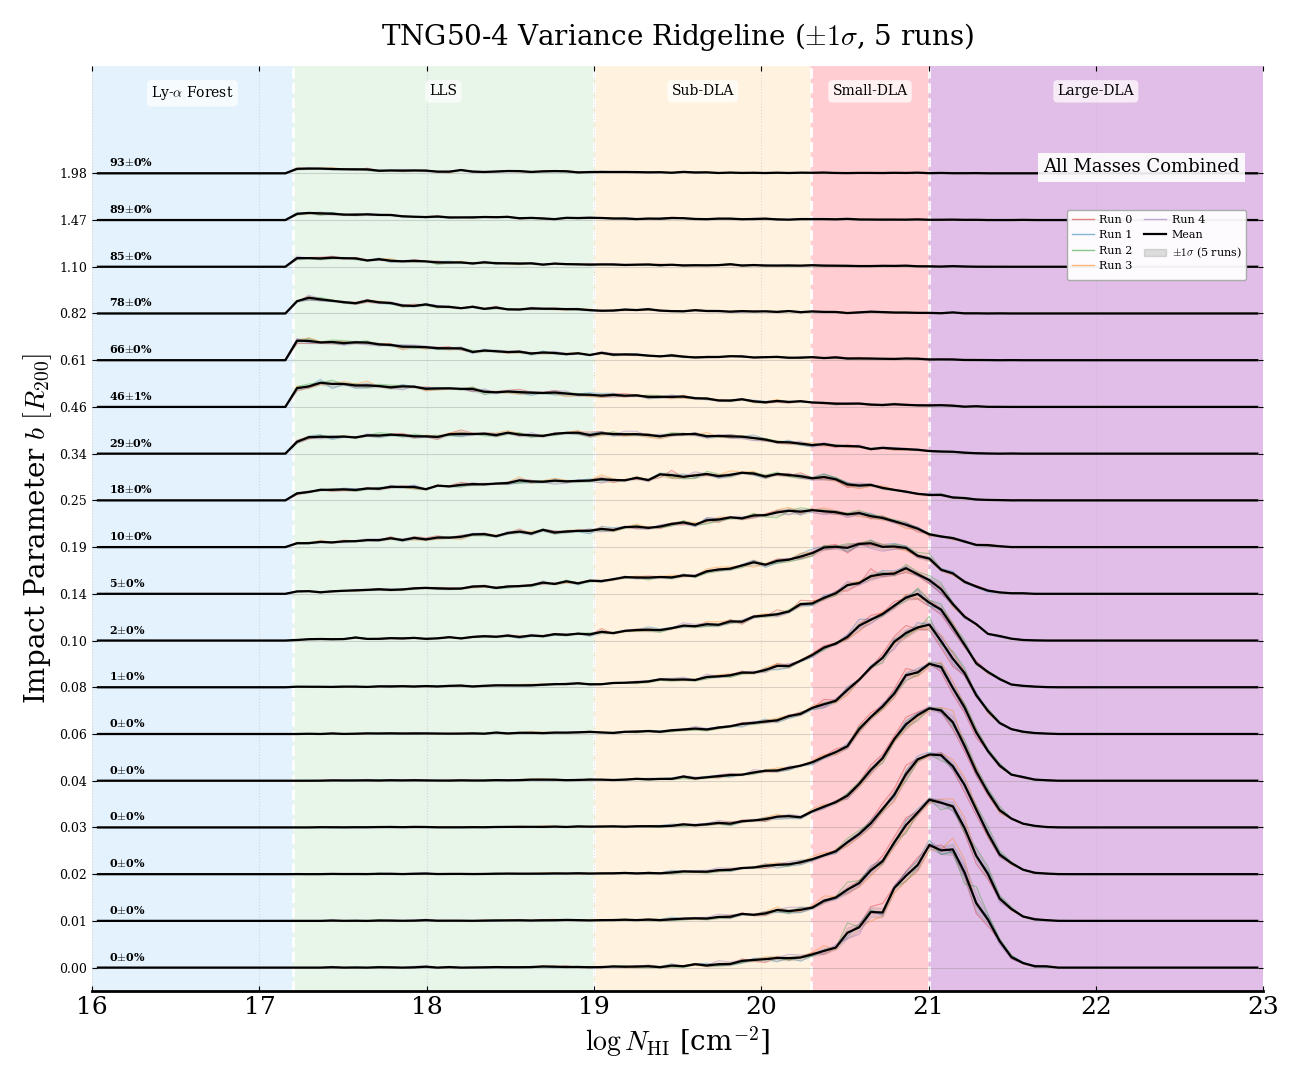

In [8]:
# ==========================================================================
# PLOT A: RIDGELINE — ALL MASSES COMBINED
# ==========================================================================
fig_height_all = max(8, 0.60 * n_sel)
fig_all, ax_all = plt.subplots(figsize=(13, fig_height_all))

paint_ridgeline(
    ax_all, dfs_runs, SELECTED_B,
    mass_low=None, mass_high=None,
    title_text='All Masses Combined',
    show_legend=True,
)

ax_all.set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]")
ax_all.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')
ax_all.set_title(
    rf'TNG50-4 Variance Ridgeline ($\pm{NSIGMA_RIDGE}\sigma$, {n_runs} runs)',
    pad=15,
)

plt.tight_layout()
plt.show()

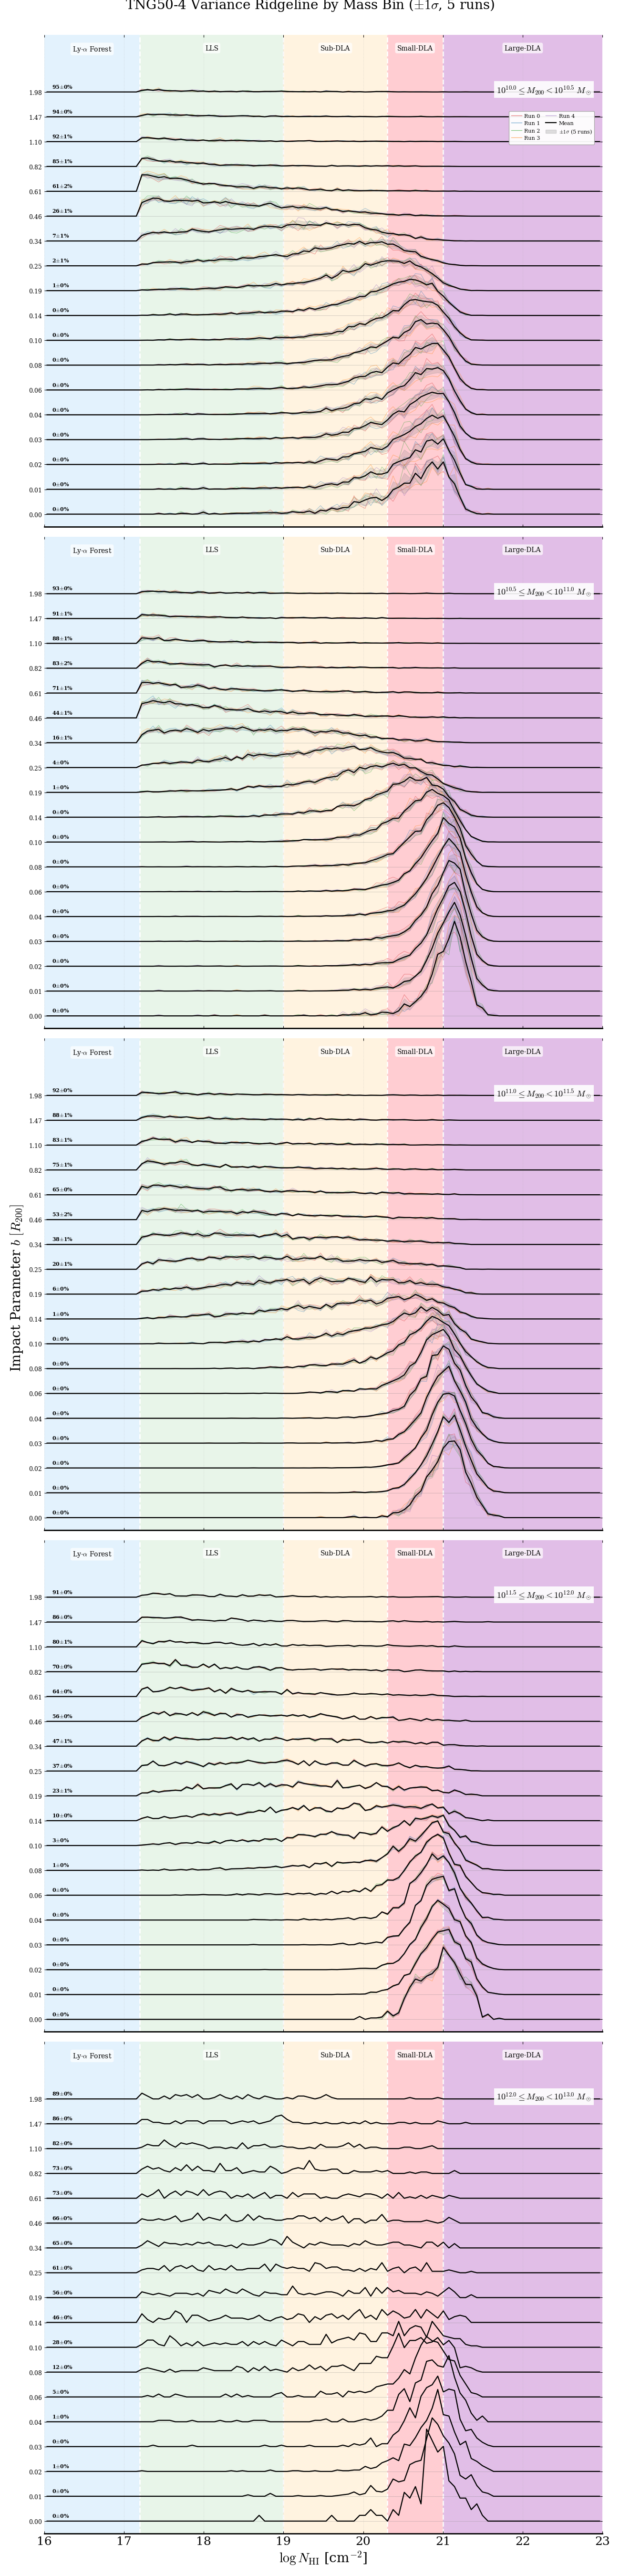

In [9]:
# ==========================================================================
# PLOT B: RIDGELINE — SPLIT BY MASS BIN
# ==========================================================================
fig_height_mass = max(6, 0.60 * n_sel)
fig_mass, axes_mass = plt.subplots(
    n_mass_bins, 1,
    figsize=(13, fig_height_mass * n_mass_bins),
    sharex=True,
)
if n_mass_bins == 1:
    axes_mass = np.array([axes_mass])

for i_m, (m_low, m_high, m_label) in enumerate(
        zip(mass_edges[:-1], mass_edges[1:], mass_labels)):

    paint_ridgeline(
        axes_mass[i_m], dfs_runs, SELECTED_B,
        mass_low=m_low, mass_high=m_high,
        title_text=m_label,
        show_legend=(i_m == 0),
    )

axes_mass[-1].set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]")
fig_mass.text(
    0.015, 0.5,
    r'Impact Parameter $b \ [R_{200}]$',
    va='center', rotation='vertical', fontsize=20,
)

fig_mass.suptitle(
    rf'TNG50-4 Variance Ridgeline by Mass Bin '
    rf'($\pm{NSIGMA_RIDGE}\sigma$, {n_runs} runs)',
    fontsize=20, y=1.001,
)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()

In [10]:
# ==========================================================================
# TERMINAL: SUMMARY TABLE
# ==========================================================================
print("\n" + "=" * 115)
print(f"  FOREST FRACTION (log NHI < 17.2) AT ALL IMPACT PARAMETERS — {n_runs} RUNS")
print(f"  Format: Total% (>0%)")
print("=" * 115)

header = f"{'b [R200]':>10}"
for r in range(n_runs):
    header += f" | {'Run '+str(r):>11}"
header += f" | {'Mean(>0%)':>13} | {'±1σ':>8}"
print(header)
print("-" * 115)

for b_val in SELECTED_B:
    b_round = np.round(b_val, 2)
    row = f"{b_val:>10.2f}"
    pcts = []
    pcts_nz = []

    for r_idx, df_run in enumerate(dfs_runs):
        df_b = df_run[df_run['r_mult_round'] == b_round]
        tot  = len(df_b)
        if tot > 0:
            p    = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            p_nz = len(df_b[(df_b['log_n_hi'] > 0) & (df_b['log_n_hi'] < 17.2)]) / tot * 100
        else:
            p    = np.nan
            p_nz = np.nan
            
        pcts.append(p)
        pcts_nz.append(p_nz)
        row += f" | {p:>5.1f}%({p_nz:>3.1f}%)"

    arr    = np.array(pcts)
    arr_nz = np.array(pcts_nz)
    row += f" | {np.nanmean(arr):>5.1f}%({np.nanmean(arr_nz):>3.1f}%) | {np.nanstd(arr):>7.1f}%"
    print(row)

print("=" * 115 + "\n")


  FOREST FRACTION (log NHI < 17.2) AT ALL IMPACT PARAMETERS — 5 RUNS
  Format: Total% (>0%)
  b [R200] |       Run 0 |       Run 1 |       Run 2 |       Run 3 |       Run 4 |     Mean(>0%) |      ±1σ
-------------------------------------------------------------------------------------------------------------------
      0.00 |   0.1%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |     0.0%
      0.01 |   0.1%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |     0.0%
      0.02 |   0.1%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |     0.0%
      0.03 |   0.1%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |   0.1%(0.0%) |   0.0%(0.0%) |   0.0%(0.0%) |     0.0%
      0.04 |   0.1%(0.0%) |   0.1%(0.0%) |   0.1%(0.0%) |   0.1%(0.0%) |   0.1%(0.0%) |   0.1%(0.0%) |     0.0%
      0.06 |   0.4%(0.0%) |   0.3%(0.0%) |   0.3%(0.0%) |   0.4%(0.0%) |   0.4%(0.0%) |   0.4%(0.0%) |     0.0%
      0.08 

In [11]:
# ==============================================================================
# CELL 6: PERCENTAGE TABLE AT MAX RADIUS (MEAN ± STD)
# ==============================================================================
max_b = unique_radii.max()

print("\n" + "="*90)
print(f" ABSORBER FRACTIONS AT b = {max_b:.2f} R_200 (TNG50-4, {n_runs} runs)")
print("="*90)
print(f"{'Run / Stat':<16} | {'L-DLA':>10} | {'S-DLA':>10} | {'Sub-DLA':>10} | {'LLS':>10} | {'Forest':>10}")
print("-" * 90)

all_percentages = []

for i, df_run in enumerate(dfs_runs):
    df_b = df_run[df_run['r_mult_round'] == max_b]
    tot = len(df_b)
    
    if tot > 0:
        nhi = df_b['log_n_hi']
        pcts = [
            (len(nhi[nhi >= 21.0]) / tot) * 100,
            (len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot) * 100,
            (len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot) * 100,
            (len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot) * 100,
            (len(nhi[nhi < 17.2]) / tot) * 100,
        ]
        all_percentages.append(pcts)
        print(f"{'Run '+str(i):<16} | {pcts[0]:>9.2f}% | {pcts[1]:>9.2f}% | {pcts[2]:>9.2f}% | {pcts[3]:>9.2f}% | {pcts[4]:>9.2f}%")

if all_percentages:
    print("-" * 90)
    arr = np.array(all_percentages)
    means = np.mean(arr, axis=0)
    stds  = np.std(arr, axis=0)
    
    print(f"{'Mean':<16} | {means[0]:>9.2f}% | {means[1]:>9.2f}% | {means[2]:>9.2f}% | {means[3]:>9.2f}% | {means[4]:>9.2f}%")
    print(f"{'± 1σ':<16} | {stds[0]:>9.2f}% | {stds[1]:>9.2f}% | {stds[2]:>9.2f}% | {stds[3]:>9.2f}% | {stds[4]:>9.2f}%")

print("="*90)
print(f"\nGRID ({total_grid_skewers:,} skewers):")
print(f"{'Grid':<16} | {grid_fractions['Large_DLA']*100:>9.2f}% | {grid_fractions['Small_DLA']*100:>9.2f}% | {grid_fractions['Sub_DLA']*100:>9.2f}% | {grid_fractions['LLS']*100:>9.2f}% | {grid_fractions['Forest']*100:>9.2f}%")
print("="*90 + "\n")


 ABSORBER FRACTIONS AT b = 50.00 R_200 (TNG50-4, 5 runs)
Run / Stat       |      L-DLA |      S-DLA |    Sub-DLA |        LLS |     Forest
------------------------------------------------------------------------------------------
Run 0            |      0.03% |      0.01% |      0.10% |      0.37% |     99.49%
Run 1            |      0.03% |      0.03% |      0.09% |      0.29% |     99.57%
Run 2            |      0.01% |      0.01% |      0.09% |      0.35% |     99.53%
Run 3            |      0.00% |      0.01% |      0.03% |      0.30% |     99.66%
Run 4            |      0.00% |      0.01% |      0.07% |      0.35% |     99.57%
------------------------------------------------------------------------------------------
Mean             |      0.01% |      0.02% |      0.08% |      0.33% |     99.56%
± 1σ             |      0.01% |      0.01% |      0.03% |      0.03% |      0.06%

GRID (750,000 skewers):
Grid             |      0.09% |      0.53% |      1.69% |      6.31% |     91.3